In [1]:
# === Google Colab 自動環境セットアップ ===
# ※ローカル環境では安全に無視され、Colab環境でのみ自動実行されます
import os, sys
repo_root = os.path.abspath(os.path.join(os.getcwd(), "..")) if os.path.exists("../common") else os.path.abspath(os.getcwd())
if "google.colab" in sys.modules:
    print("⚡ Google Colab 環境を検出しました。リポジトリのセットアップを開始します...")
    !git clone https://github.com/miyayudai/study-mikanos.git /content/study-mikanos 2>/dev/null || (cd /content/study-mikanos && git pull)
    %cd /content/study-mikanos
    !pip install -q -r requirements.txt
    !pip install -q -e .
    repo_root = "/content/study-mikanos"
    sys.path.insert(0, repo_root)
    print("✅ 環境セットアップが完了しました。作業ディレクトリ:", os.getcwd())
else:
    if repo_root not in sys.path:
        sys.path.insert(0, repo_root)
    print("💻 ローカル開発環境を検出しました。リポジトリルート:", repo_root)



💻 ローカル開発環境を検出しました。リポジトリルート: /home/student/Documents/GitHub/study-mikanos


# 8.5 セグメンテーションの設定 (`osbook_day08b` / `day08c`)
### *Configuring Global Descriptor Table (GDT), 64-bit Long Mode Invariants, and CS Switching via iretq*

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/miyayudai/study-mikanos/blob/main/8/8.5_Setting_Up_GDT_Segmentation.ipynb)

> [!IMPORTANT]
> **学習目標 (Objectives)**:
> 1. なぜページング（Paging）が主流となった現代の 64 ビット x86-64 アーキテクチャにおいても **GDT (*Global Descriptor Table*)** の設定が必須なのか、その歴史的背景とハードウェア仕様上の理由を理解する。
> 2. 64 ビット **`SegmentDescriptor` (セグメント記述子)** の複雑なビットレイアウト（Base, Limit, Type, S, DPL, P, L, D/B, G）の数理構造と、Long Mode（64 ビットモード）におけるフラットモデル（Flat Memory Model）の解釈を完全修得する。
> 3. C++ のビットフィールド共用体における符号拡張の罠（`enum class DescriptorType : uint8_t`）を回避し、安全な GDT 配列を構築する。
> 4. 16 ビット **セグメントセレクタ (*Segment Selector*)** の内部ビット構造（Index, TI, RPL）と、カーネルコードセレクタ `0x08`、ユーザコードセレクタ `0x13` の導出式を理解する。
> 5. **`LGDT` 命令** による 10 バイト擬似記述子（GDTR Pointer）のロード手順、および CPU が `mov cs, ax` を厳禁とする理由と **`iretq` (割り込み復帰命令) を利用したアトミックな CS レジスタ切り替え** の仕組みを解剖する。



---

## 8.5.1 セグメンテーションの歴史と x86-64 における必然性

### 1. セグメンテーションの歴史的変遷

x86 アーキテクチャにおけるセグメンテーション（*Segmentation*）は、CPU の世代交代とともにその役割を劇的に変化させてきました。

| CPU 世代 | 動作モード | アドレス幅 | メモリアクセス方式 | セグメントレジスタの役割 |
|:---:|:---:|:---:|---|---|
| **8086** (1978年) | リアルモード (*Real Mode*) | 20 ビット (1 MiB) | `物理アドレス = (セグメント << 4) + オフセット` | 16 ビットの基底アドレスを保持（保護機能なし） |
| **80286** (1982年) | 16ビット プロテクトモード | 24 ビット (16 MiB) | GDT/LDT 記述子テーブルを参照し Base + Limit チェック | GDT/LDT のインデックスを示すセレクタ（保護機能あり） |
| **80386** (1985年) | 32ビット プロテクトモード | 32 ビット (4 GiB) | ページング機構が追加。セグメントで線形アドレスを生成し、ページテーブルで物理アドレスへ変換 | Base=0, Limit=4GiB の「フラットモデル」が主流化 |
| **x86-64 / AMD64** (2003年〜現在) | **ロングモード (*Long Mode*)** | 64 ビット (理論上 16 EiB, 実装上 48/57 ビット) | **セグメンテーションのベース/リミットチェックは事実上無効化（フラットモデル強制）**。メモリ保護と仮想記憶はすべてページングに集約 | **CPU 動作モード（64-bit モード指示）と特権レベル（Ring 0 vs Ring 3）の定義のみに使用** |

### 2. なぜ x86-64 でも GDT を設定しなければならないのか？

「現代の OS はページングでメモリを管理しているのだから、セグメンテーションは不要ではないか？」という疑問は非常に自然です。実際、x86-64 の Long Mode において、ハードウェアはコードおよびデータの **ベースアドレス（Base Address）を強制的に 0** とみなし、**リミット（Segment Limit）による境界チェックも行いません**。

しかし、Intel / AMD の x86-64 アーキテクチャ仕様書において、**GDT は依然として絶対に省略できない中核機構** です。その理由は以下の 3 点に集約されます：

1. **CPU に「64 ビット Long Mode コード」を実行させる指示フラグ（L ビット）**:
   x86-64 CPU は、64 ビットモード（Long Mode）だけでなく、従来の 32 ビットバイナリをそのまま実行する「互換モード（*Compatibility Mode*）」をサポートしています。CPU のデコーダは、現在実行中のコードセグメント記述子の **L ビット（Long Mode フラグ, bit 53）** が `1` であるか `0` であるかを見て、64 ビット機械語命令としてデコードするか、32 ビット命令としてデコードするかを決定します。
2. **ハードウェア特権レベル（CPL / DPL: Ring 0 vs Ring 3）の厳格な分離**:
   CPU の現在の特権レベル **CPL (*Current Privilege Level*)** は、CS（Code Segment）レジスタが指すセグメント記述子の **DPL (*Descriptor Privilege Level*)** によって決定されます。カーネルモード（Ring 0）とユーザアプリケーション（Ring 3）を分離するためには、DPL=0 のコードセグメントと DPL=3 のコードセグメントを GDT に定義することが不可欠です。
3. **将来のマルチタスク・例外処理基盤（TSS / IST）**:
   第20章以降で登場する **TSS (*Task State Segment*)** や、カーネルスタックの自動切り替えを行う **IST (*Interrupt Stack Table*)** は、GDT 内に「システムセグメント記述子」として登録されます。

### 3. UEFI の GDT のまま動かしてはいけない理由

UEFI BIOS は、ブートローダおよびカーネルを呼び出す時点で、自身が初期化した一時的な GDT を使用して CPU を 64 ビット Long Mode で動作させています。
しかし、`ExitBootServices()` を呼び出してファームウェアの管理下を離れた後、**UEFI が設定した GDT のメモリ領域（Firmware 領域）はいつ上書きされてもおかしくありません**。また、UEFI の GDT には OS 独自の Ring 3 アプリケーション用コードセグメントや TSS は定義されていません。
したがって、OS が完全にハードウェアの支配権を握るためには、**自前のメモリ領域（カーネルの静的データ領域）に独自の GDT を構築し、CPU の GDTR レジスタを自前の GDT に向け直す** ことが必須となります。



---

## 8.5.2 64 ビット `SegmentDescriptor` の詳細ビットレイアウトと数理導出

### 1. セグメント記述子のビットレイアウト

x86-64 の標準セグメント記述子は **64 ビット（8 バイト）** の固定長データ構造です。
そのビットフィールド配置は、80286（24 ビット）および 80386（32 ビット）との下位互換性を保ちながら拡張されてきた歴史的経緯により、極めて入り組んだ（Scattered）構造をしています。

```
 63       56 55 54 53 52 51    48 47 46 45 44 43    40 39       32
+-----------+--+--+--+--+--------+--+-----+--+--------+-----------+
| Base High |G |D |L |A | Limit  |P | DPL |S |  Type  | Base Mid  |  (High 32 bits)
|  [31:24]  |  |B |  |V | [19:16]|  |     |  |        |  [23:16]  |
+-----------+--+--+--+--+--------+--+-----+--+--------+-----------+

 31                            16 15                             0
+--------------------------------+--------------------------------+
|           Base Low             |        Segment Limit           |  (Low 32 bits)
|           [15:0]               |            [15:0]              |
+--------------------------------+--------------------------------+
```

各フィールドの定義と Long Mode における役割は以下の通りです：

| ビット範囲 | フィールド名 | ビット幅 | 説明と MikanOS での設定値 |
|:---:|---|:---:|---|
| **0..15** | `limit_low` | 16 | リミットの下位 16 ビット。MikanOS では `0xFFFF`。 |
| **16..31** | `base_low` | 16 | ベースアドレスの下位 16 ビット。Long Mode ではフラットモデルのため `0`。 |
| **32..39** | `base_middle` | 8 | ベースアドレスの中位 8 ビット（bits 16..23）。`0`。 |
| **40..43** | `type` | 4 | セグメントの種類。コードセグメントの場合 `10` (`0b1010`: Execute/Read, non-conforming)。 |
| **44** | `system_segment` (S) | 1 | 記述子種別。`1`: コード/データセグメント、`0`: システム記述子（TSS, LDT 等）。 |
| **45..46** | `descriptor_privilege_level` (DPL) | 2 | 特権レベル。`0`: カーネル (Ring 0)、`3`: ユーザ (Ring 3)。 |
| **47** | `present` (P) | 1 | セグメントの有効性。`1`: メモリ上に有効に存在、`0`: 無効（アクセス時 `#NP` 例外）。 |
| **48..51** | `limit_high` | 4 | リミットの上位 4 ビット（bits 16..19）。MikanOS では `0xF`。合計リミットは `0xFFFFF`。 |
| **52** | `available` (AVL) | 1 | OS ソフトウェア用自由予約フラグ。`0`。 |
| **53** | `long_mode` (L) | 1 | **64 ビットコードフラグ**。`1`: 64 ビット Long Mode、`0`: 互換モード（Compatibility Mode）。 |
| **54** | `default_operation_size` (D/B) | 1 | デフォルトオペランドサイズ。**L=1 のときは必ず 0 に設定することが Intel SDM で義務付けられている**。 |
| **55** | `granularity` (G) | 1 | リミットの単位。`1`: 4 KiB ページ単位、`0`: 1 バイト単位。MikanOS では `1`。 |
| **56..63** | `base_high` | 8 | ベースアドレスの最上位 8 ビット（bits 24..31）。`0`。 |

### 2. 有効リミット（Effective Limit）の数理導出

リミットフィールドは `limit_high` (4 ビット) と `limit_low` (16 ビット) の結合により **20 ビット** の整数値 $L_{\text{raw}}$ を形成します：
$$L_{\text{raw}} = (\text{limit\_high} \ll 16) \mid \text{limit\_low} = 0x0F \ll 16 \mid 0xFFFF = 0x000FFFFF = 1,048,575$$

粒度フラグ **G (Granularity, bit 55)** が `1` の場合、ハードウェアはこの値に 4 KiB ($2^{12} = 4096$ バイト) を乗じ、下位 12 ビットをすべて 1 とみなして有効リミット $L_{\text{eff}}$ を算出します：
$$L_{\text{eff}} = (L_{\text{raw}} + 1) \times 4096 - 1 = (1,048,575 + 1) \times 4096 - 1 = 4,294,967,296 - 1 = 0xFFFFFFFF \text{ (4 GiB)}$$
※ x86-64 Long Mode においてはハードウェアがリミットチェックをスキップするため、実質的に 64 ビット仮想アドレス空間全体（Canonical Address 全域）がアクセス対象となります。

### 3. C++ 実装と符号付きビットフィールドの落とし穴

MikanOS の `kernel/segment.hpp` では、この 64 ビット記述子を共用体 `union SegmentDescriptor` として美しく定義しています：

```cpp
union SegmentDescriptor {
  uint64_t data;
  struct {
    uint64_t limit_low : 16;
    uint64_t base_low : 16;
    uint64_t base_middle : 8;
    DescriptorType type : 4;                 // ⚠️ 要注意ポイント！
    uint64_t system_segment : 1;
    uint64_t descriptor_privilege_level : 2;
    uint64_t present : 1;
    uint64_t limit_high : 4;
    uint64_t available : 1;
    uint64_t long_mode : 1;
    uint64_t default_operation_size : 1;
    uint64_t granularity : 1;
    uint64_t base_high : 8;
  } __attribute__((packed)) bits;
} __attribute__((packed));
```

> [!WARNING]
> **C++ のビットフィールドと signed/unsigned 列挙型の落とし穴**:
> `enum class DescriptorType` を基底型指定なし（デフォルトの `int`）で定義すると、4 ビットのビットフィールド `DescriptorType type : 4` において、値 `10` (`0b1010`) の最上位ビットが符号ビットとみなされ、`-6` に符号拡張されてしまいます！
> これにより `desc.bits.type == DescriptorType::kExecuteRead` の比較が予期せず偽（false）になるバグが生じます。
> したがって、基底型を明示して **`enum class DescriptorType : uint8_t`** と定義することが極めて重要です。



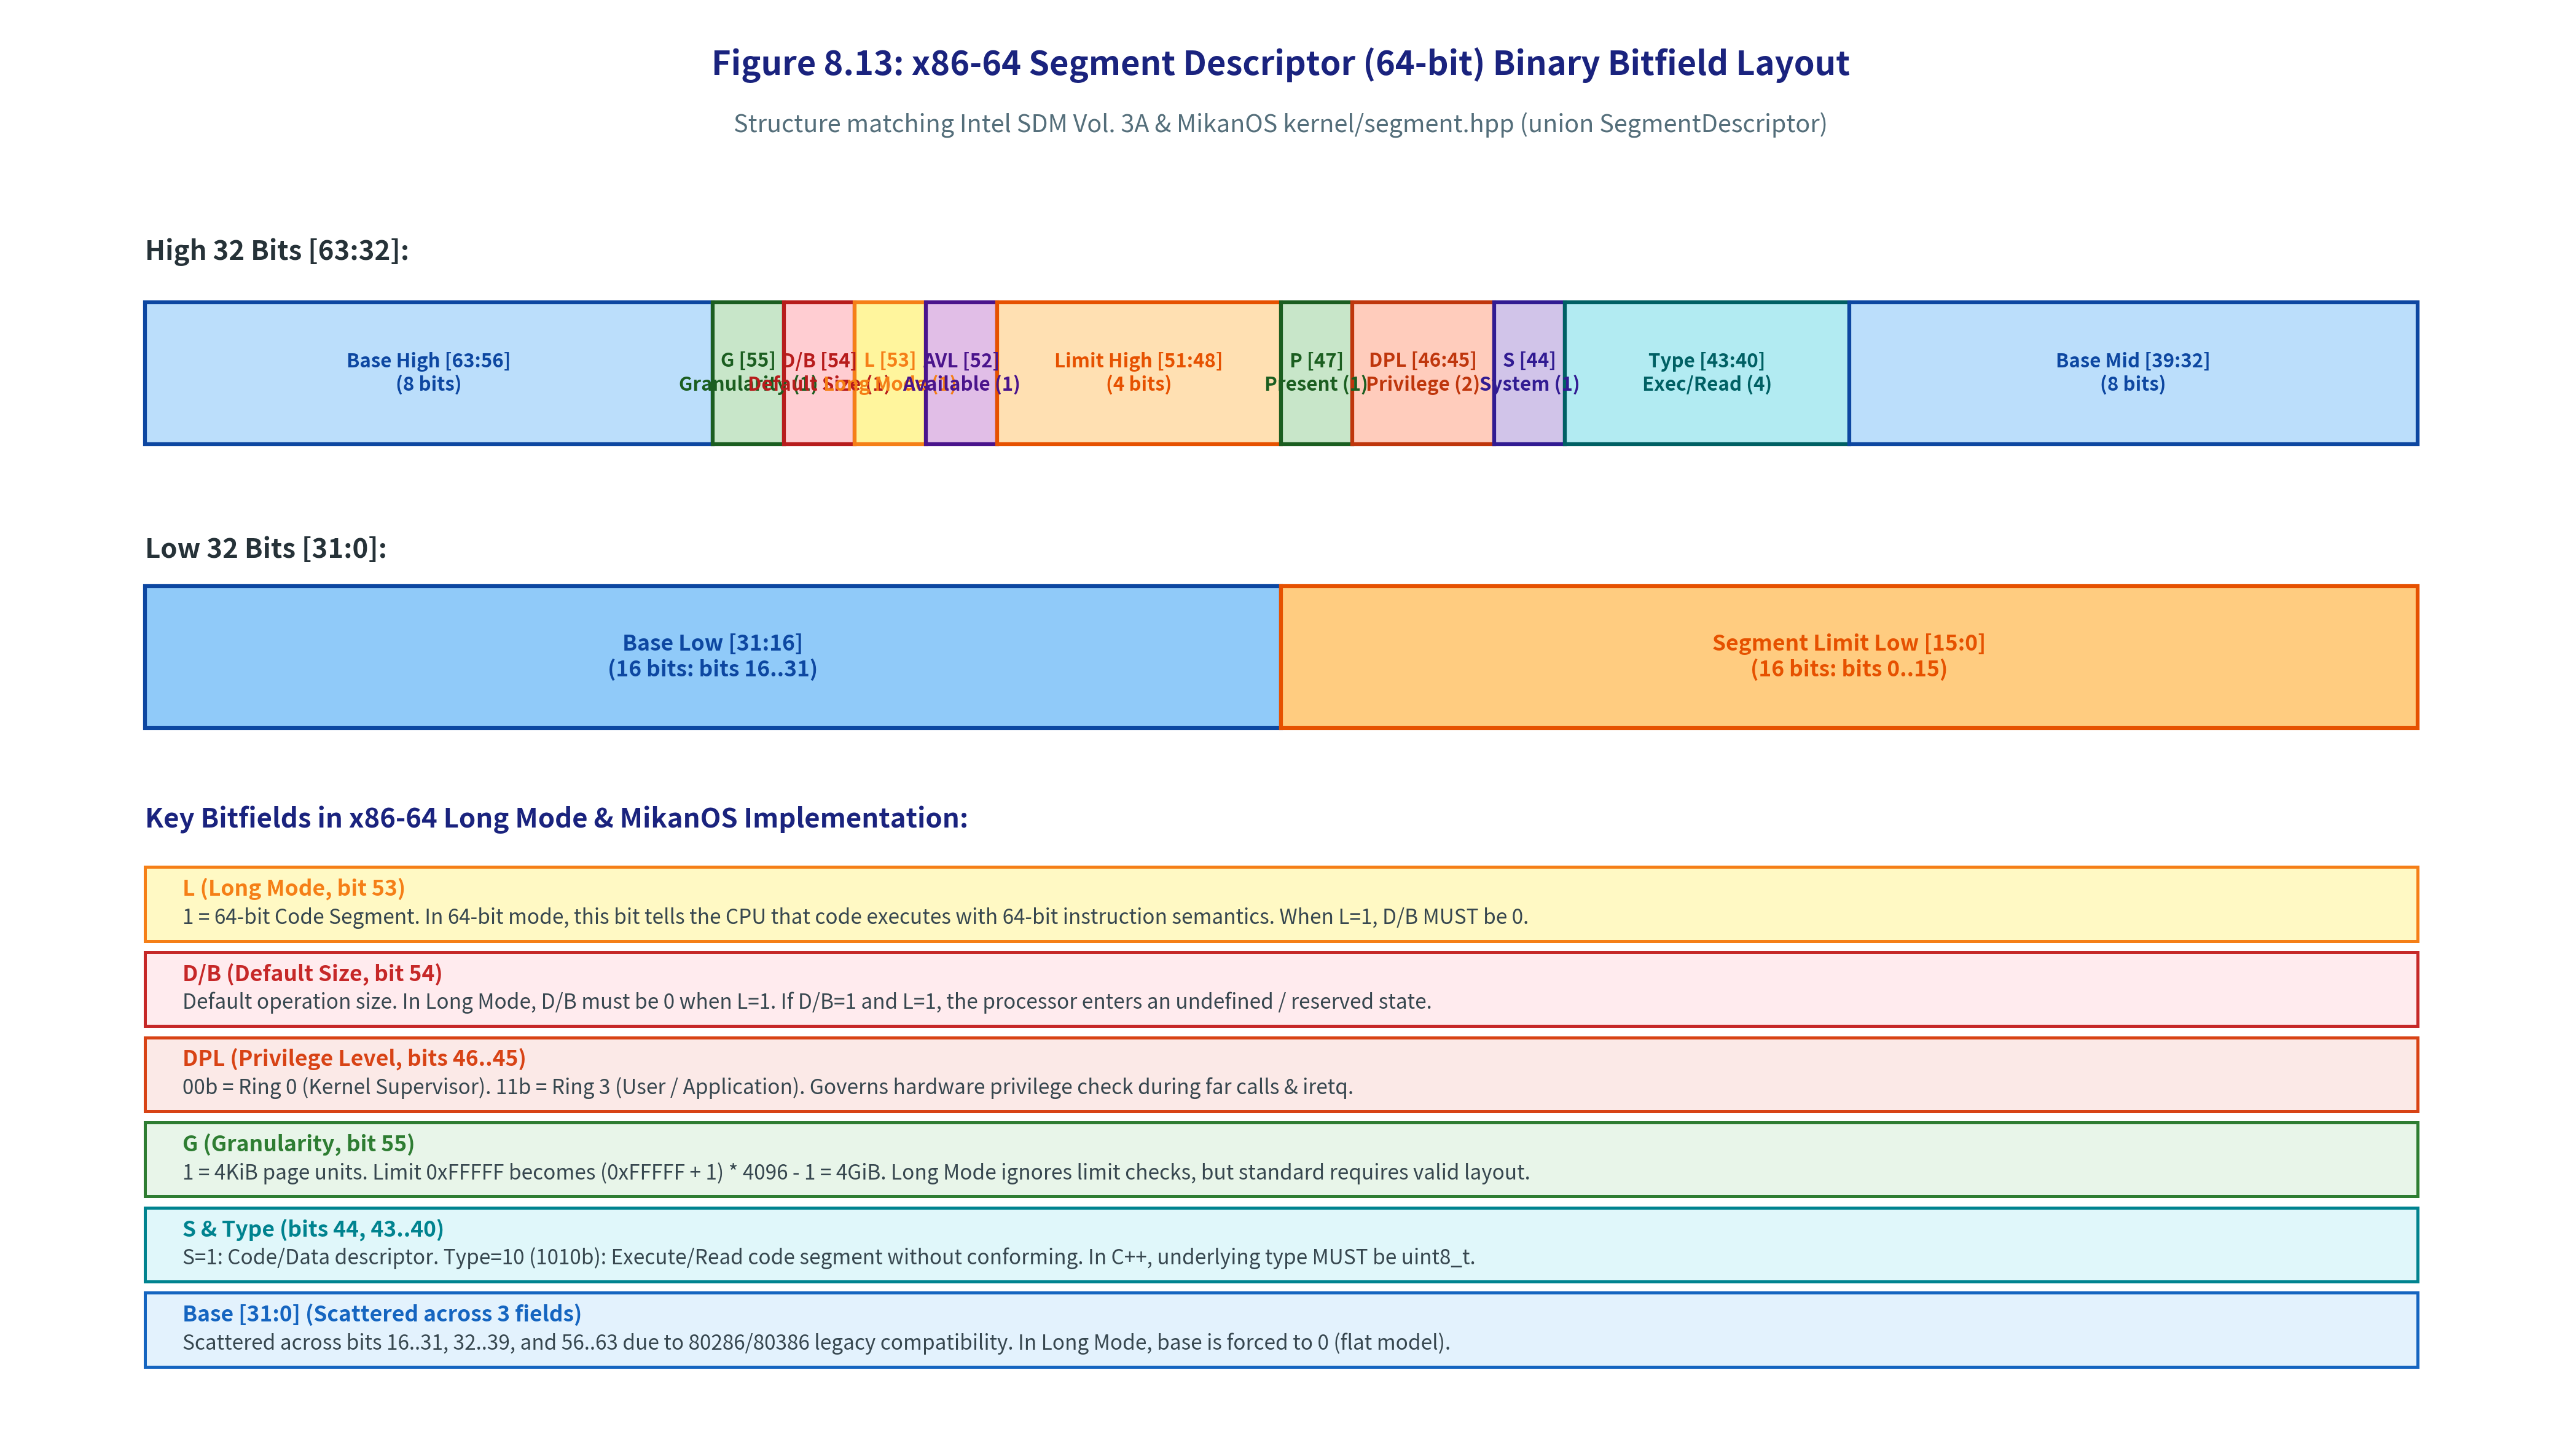

In [2]:
# 図版 8.13 の生成と表示
from common.os_sim import plot_fig8_13_gdt_descriptor_bit_layout, SegmentDescriptorSim
from IPython.display import Image, display

fig8_13_path = plot_fig8_13_gdt_descriptor_bit_layout("8/result/fig8_13_gdt_descriptor_bit_layout.png")
display(Image(fig8_13_path))



### 図版 8.13 の解説: 64ビット `SegmentDescriptor` のバイナリ構造

図版 8.13 は、Intel SDM に規定された x86-64 セグメント記述子のビットレイアウトを示しています：
1. **下位 32 ビット [31:0]**:
   - `base_low` (16..31) と `limit_low` (0..15) が格納されます。フラットモデルでは Base は常に 0 です。
2. **上位 32 ビット [63:32]**:
   - `base_high` [63:56] と `base_middle` [39:32] に分断されたベースアドレス、および各制御フラグ（G, D/B, L, AVL, Limit High, P, DPL, S, Type）が集約されています。
3. **MikanOS カーネルコード記述子の 64 ビット値**:
   - DPL=0, Type=10, S=1, P=1, L=1, D/B=0, G=1, Limit=0xFFFFF, Base=0 をエンコードすると：
     $$\text{0x00AF\_9A00\_0000\_FFFF}$$
   - 上位 32 ビット: `0x00AF9A00`
     - bit 55 (G=1), bit 53 (L=1), bit 51..48 (LimitHigh=0xF) $\rightarrow$ `0xAF`
     - bit 47 (P=1), bit 46..45 (DPL=0), bit 44 (S=1), bit 43..40 (Type=10=0xA) $\rightarrow$ `0x9A`
   - 下位 32 ビット: `0x0000FFFF`



---

## 8.5.3 GDT テーブルの構築と 16 ビット セグメントセレクタ

### 1. MikanOS 第8章における GDT の構成

MikanOS では、`kernel/segment.cpp` において 3 つの記述子からなる GDT 配列を静的に定義します：

```cpp
namespace {
  std::array<SegmentDescriptor, 3> gdt;
}

void SetupSegments() {
  gdt[0].data = 0; // GDT[0]: ヌル記述子 (Null Descriptor)
  SetCodeSegment(gdt[1], DescriptorType::kExecuteRead, 0, 0, 0xfffff); // GDT[1]: カーネル CS (Ring 0)
  SetCodeSegment(gdt[2], DescriptorType::kExecuteRead, 3, 0, 0xfffff); // GDT[2]: ユーザ CS (Ring 3)
  LoadGDT(sizeof(gdt) - 1, reinterpret_cast<uintptr_t>(&gdt[0]));
}
```

- **GDT[0]: ヌル記述子 (Null Descriptor)**:
  x86 アーキテクチャの規定により、インデックス 0 は「ヌル記述子（全ビット 0）」として予約されています。データセグメントレジスタ（DS, ES など）に 0 をロードした際、CPU は「セグメントが無効化（未使用）されている」と解釈し、即座に例外を発生させずに動作を継続できます。
- **GDT[1]: カーネルコードセグメント (Ring 0)**:
  `DPL = 0` であり、カーネルが最高特権（Supervisor）で動作するための記述子です。
- **GDT[2]: ユーザコードセグメント (Ring 3)**:
  `DPL = 3` であり、将来アプリケーションが保護されたユーザモードで動作するための記述子です。

### 2. 16 ビット セグメントセレクタ（Segment Selector）の構造と導出

CPU のセグメントレジスタ（CS, DS, SS, ES, FS, GS）に格納される値は、単なるテーブルのインデックス（0, 1, 2...）ではありません。
ハードウェア仕様として、**16 ビットの構造体** となっています：

```
 15                                      3   2   1   0
+------------------------------------------+---+-------+
|        Descriptor Index (13 bits)        |TI |  RPL  |
|                 (0..8191)                |   | (0..3)|
+------------------------------------------+---+-------+
```

| ビット範囲 | フィールド名 | ビット幅 | 説明 |
|:---:|---|:---:|---|
| **0..1** | **RPL (*Requested Privilege Level*)** | 2 | 要求特権レベル。`0` (Ring 0, 最高特権) 〜 `3` (Ring 3, ユーザ特権)。 |
| **2** | **TI (*Table Indicator*)** | 1 | 参照テーブル指定。`0`: **GDT** を参照、`1`: **LDT (*Local Descriptor Table*)** を参照。 |
| **3..15** | **Index** | 13 | 記述子テーブル内のエントリ番号（0〜8191 の最大 8192 個）。 |

#### セレクタ計算式の導出:
$$\text{Selector} = (\text{Index} \ll 3) \mid (\text{TI} \ll 2) \mid \text{RPL}$$

1. **カーネルコードセレクタ (`kernel_cs`)**:
   - Index = 1 (GDT[1]), TI = 0 (GDT), RPL = 0 (Ring 0)
   - $\text{kernel\_cs} = (1 \ll 3) \mid (0 \ll 2) \mid 0 = 8 = \mathbf{0x08}$
2. **ユーザコードセレクタ (`user_cs`)**:
   - Index = 2 (GDT[2]), TI = 0 (GDT), RPL = 3 (Ring 3)
   - $\text{user\_cs} = (2 \ll 3) \mid (0 \ll 2) \mid 3 = 16 + 3 = 19 = \mathbf{0x13}$
3. **ヌルセレクタ (`null_selector`)**:
   - Index = 0, TI = 0, RPL = 0 $\rightarrow$ $\mathbf{0x00}$



---

## 8.5.4 GDTR レジスタと `LoadGDT` (`LGDT`) 命令

### 1. GDTR レジスタの構造 (10 バイト擬似記述子)

CPU 内部の **GDTR (*Global Descriptor Table Register*)** は、GDT の先頭アドレスと有効サイズを保持する特殊レジスタです。
64 ビット Long Mode では **10 バイト（80 ビット）** の構造を持ちます：

```
 79                                              16 15                0
+--------------------------------------------------+-------------------+
|            Base Address (64 bits)                |  Limit (16 bits)  |
+--------------------------------------------------+-------------------+
```
- **Limit (16 ビット)**:
  テーブルの「サイズ - 1」バイト。GDT が 3 エントリ（$3 \times 8 = 24$ バイト）の場合、$\text{Limit} = 24 - 1 = \mathbf{23}$ (`0x17`) となります。
- **Base Address (64 ビット)**:
  メモリ上に配置された GDT 配列の先頭アドレス（`reinterpret_cast<uintptr_t>(&gdt[0])`）。

### 2. `LoadGDT` のアセンブリ実装 (`kernel/asmfunc.asm`)

x86-64 には GDTR に値を設定するための **`lgdt` (Load Global Descriptor Table)** 命令が存在します。この命令は、メモリ上の 10 バイトのポインタ領域をオペランドに取ります。

```nasm
global LoadGDT  ; void LoadGDT(uint16_t limit, uint64_t offset);
LoadGDT:
    push rbp
    mov rbp, rsp
    sub rsp, 10         ; スタック上に 10 バイトのローカル領域を確保
    mov [rsp], di       ; 第1引数 limit (16ビット: di) を書き込み
    mov [rsp + 2], rsi  ; 第2引数 offset (64ビット: rsi) を書き込み
    lgdt [rsp]          ; [rsp] が指す 10 バイトから GDTR にロード！
    mov rsp, rbp
    pop rbp
    ret
```

System V AMD64 ABI に従い、第1引数 `limit` は `DI` レジスタ、第2引数 `offset` は `RSI` レジスタで渡されます。
関数内でスタックポインタを 10 バイト下げ、`[rsp]` に limit (2バイト)、`[rsp+2]` に offset (8バイト) を書き込んでから `lgdt [rsp]` を実行することで、安全に GDTR を更新しています。



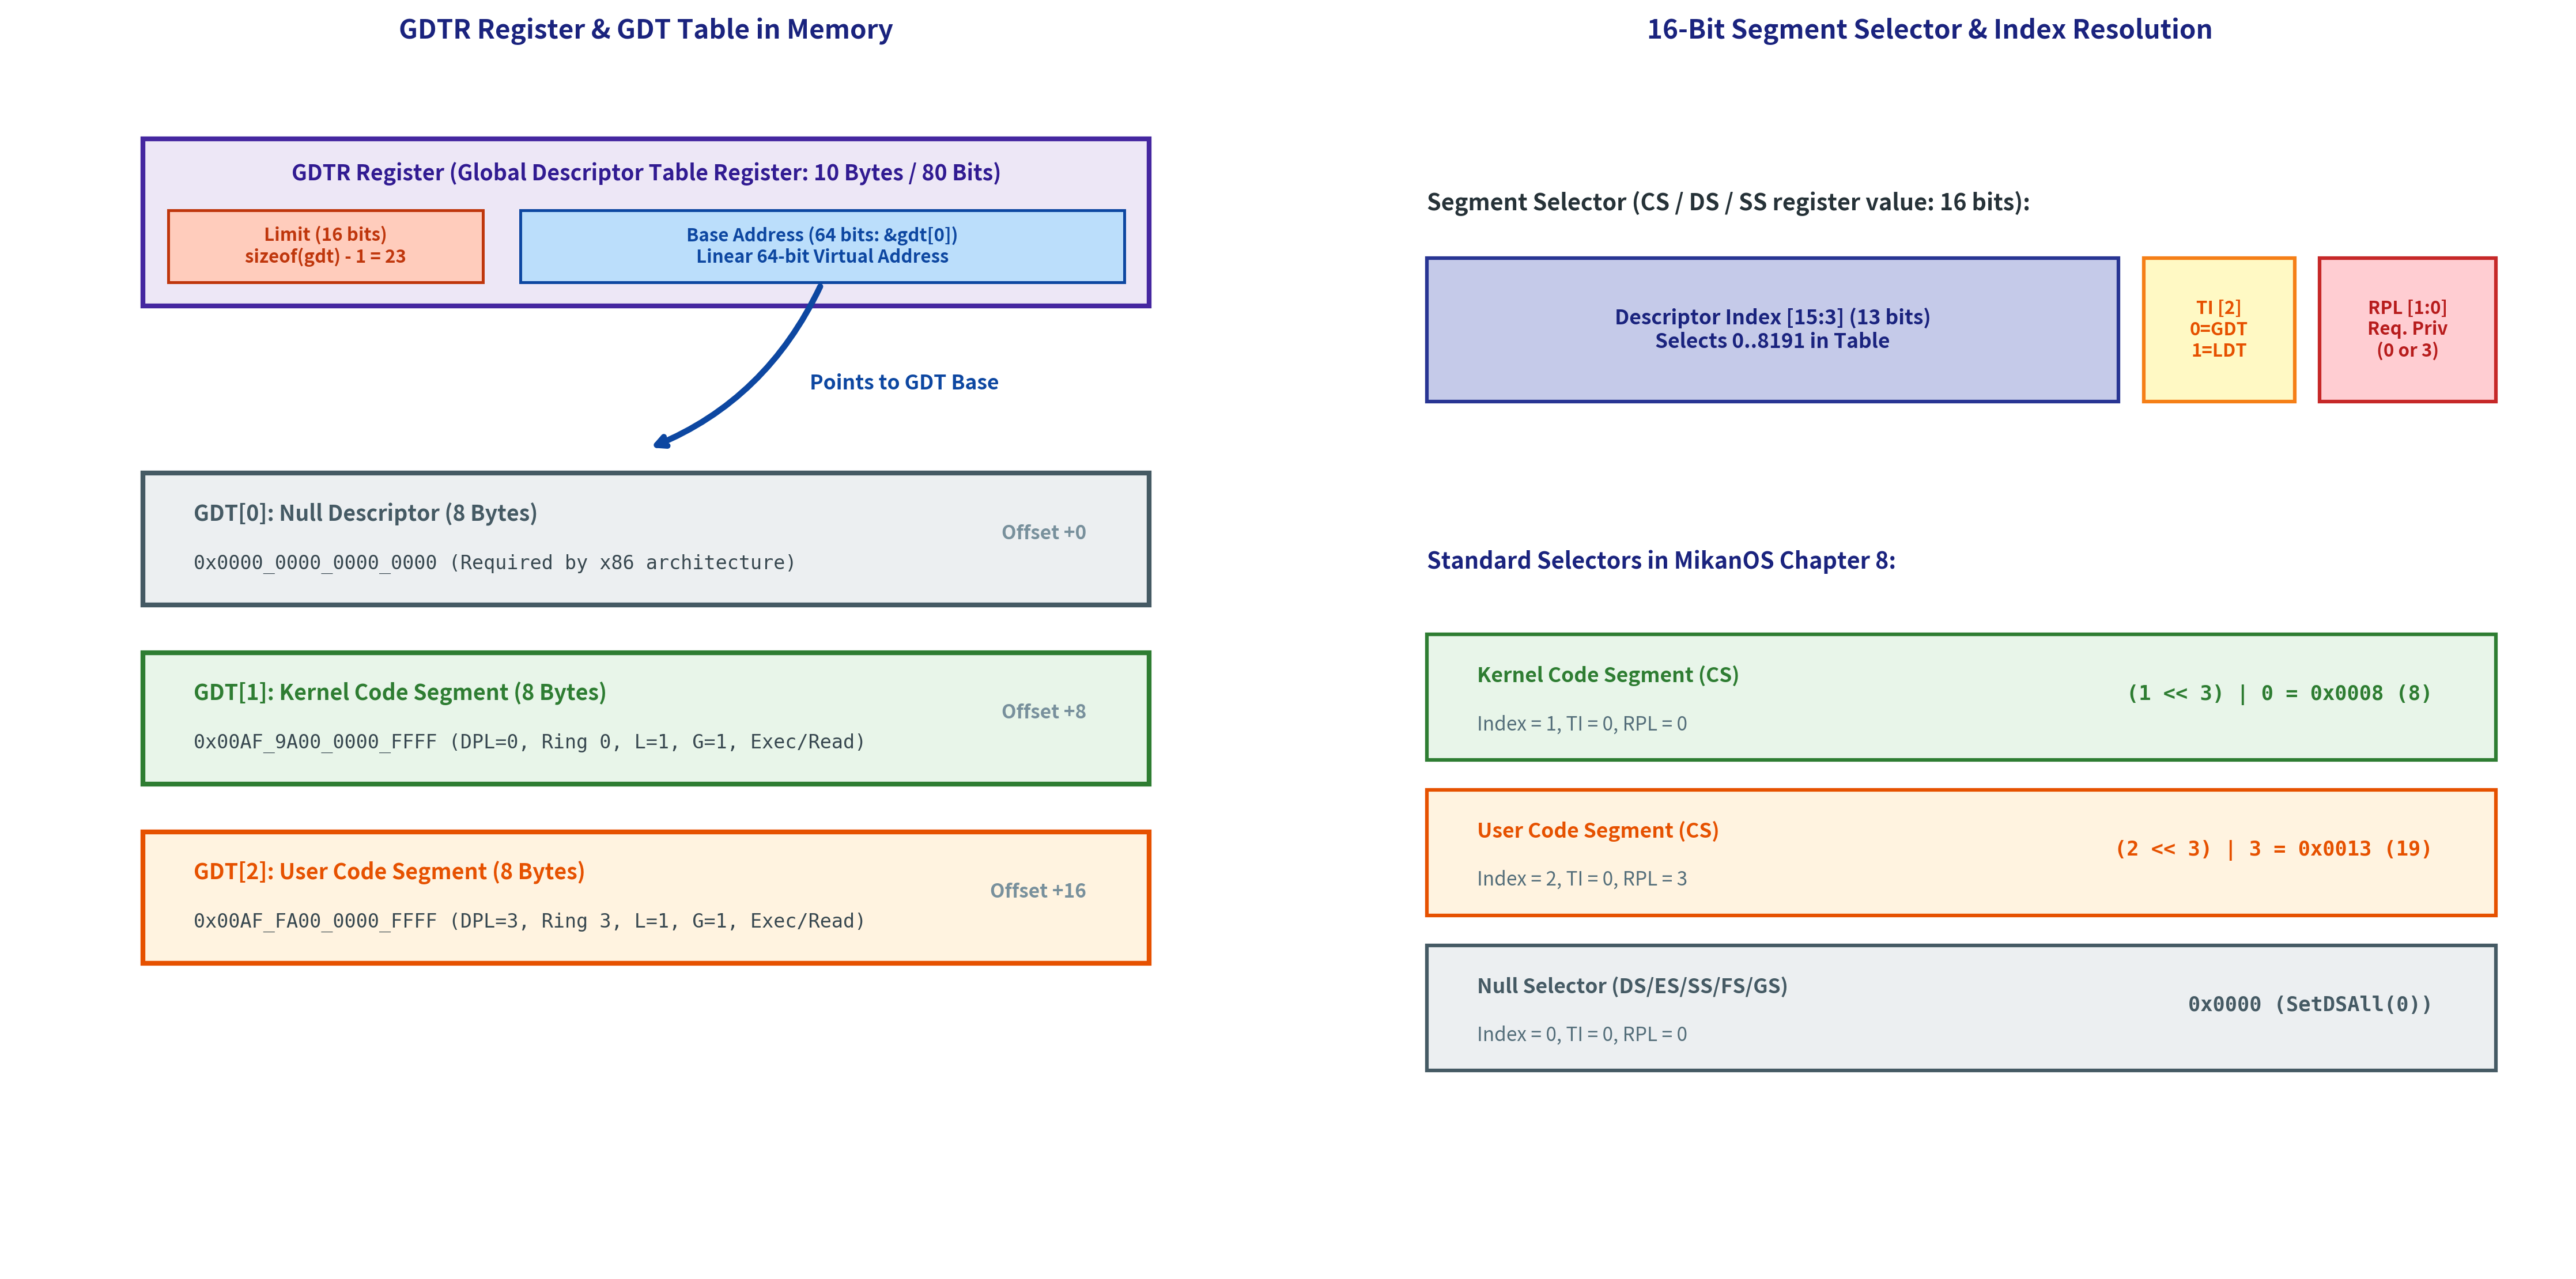

In [3]:
# 図版 8.14 の生成と表示
from common.os_sim import plot_fig8_14_gdt_table_and_gdtr_architecture
from IPython.display import Image, display

fig8_14_path = plot_fig8_14_gdt_table_and_gdtr_architecture("8/result/fig8_14_gdt_table_and_gdtr_architecture.png")
display(Image(fig8_14_path))



### 図版 8.14 の解説: GDTR とセグメントセレクタによるインデックス参照

図版 8.14 は、GDTR レジスタとメモリ上の GDT、そしてセグメントセレクタがどのように結びついているかを図解しています：
1. **左側 (GDTR と GDT テーブル)**:
   - GDTR の Base Address がメモリ上の `gdt[0]` を指し、Limit が `23` バイト（3エントリ分）の境界を定めています。
2. **右側 (16ビット セグメントセレクタ)**:
   - セレクタの上位 13 ビット（Index）が GDT 内のエントリ番号を指定します。
   - ハードウェアは `Base + (Index * 8)` を計算して該当する記述子を高速にフェッチします。
   - RPL（下位 2 ビット）が要求特権レベルを表し、記述子の DPL との特権比較に利用されます。



---

## 8.5.5 CS レジスタの更新と `iretq` の魔術

### 1. なぜ `mov cs, ax` は禁止されているのか？

GDT を新しく設定したら、CPU のコードセグメントレジスタ **`CS`** に新しいセレクタ `0x08` をロードする必要があります。
しかし、x86 アーキテクチャには **`mov cs, <reg>` という命令は存在せず、アセンブラで記述してもコンパイルエラー** になります。

なぜ CPU は CS への直接代入を拒絶するのでしょうか？
- CS レジスタの書き換えは、単にレジスタの数値を変更するだけでなく、**「CPU の特権レベル（CPL）」や「64ビット/32ビット動作モード（Lビット）」を根本から切り替える極めて危険な操作** だからです。
- もし命令ポインタ `RIP` をそのままにして CS だけを唐突に書き換えると、パイプライン内に先読み（Prefetch）された命令の特権整合性が破壊され、致命的なセキュリティホールや CPU クラッシュが発生します。
- したがって、ハードウェアは **「CS と RIP を同時に、かつアトミックにジャンプ命令として切り替える」** ことを強制しています。

### 2. CS を切り替える 3 つの手段

| 手段 | 命令形式 | メリット | デメリット・課題 |
|---|---|---|---|
| **Far Jump** | `jmp far ptr [m16:64]` | 直感的で伝統的 | 64 ビット Long Mode では直接オペランドによる 64 ビット Far Jump（`jmp 0x08:target`）がサポートされておらず、メモリ間接指定が必要で煩雑。 |
| **Far Call + Ret** | `call far ...` / `retfq` | 関数呼び出し構造 | 余計なスタック退避・復帰が発生する。 |
| **`iretq` (割り込み復帰)** | **`iretq`** | **スタック上にフレームを偽装するだけで、CS, RIP, RFLAGS, RSP, SS を完全にアトミック一括更新可能！** | 割り込みスタックフレームの構造を正確に理解する必要がある（MikanOS 採用方式）。 |

### 3. `iretq` による偽装スタックフレームの解剖

MikanOS は、割り込みハンドラからの復帰命令である **`iretq` (*Interrupt Return 64-bit*)** を巧みに利用して CS を切り替えます。

割り込みが発生した際、CPU ハードウェアはスタックに以下の 5 つの 64 ビットレジスタを自動的にプッシュします：
1. `SS` (Stack Segment)
2. `RSP` (Stack Pointer)
3. `RFLAGS` (CPU Flags)
4. `CS` (Code Segment)
5. `RIP` (Instruction Pointer)

そしてハンドラの末尾で `iretq` を実行すると、CPU はこの 5 つの値を逆順にポップして各レジスタに復元し、元の処理へ復帰します。
MikanOS の `SetCS` (`kernel/asmfunc.asm`) は、**このハードウェア仕様を逆手に取り、自らこのスタックフレームを手動で構築してから `iretq` を実行する** という鮮やかな手法を採っています：

```nasm
global SetCS  ; void SetCS(uint16_t value);
SetCS:
    push rbp
    mov rbp, rsp
    xor eax, eax
    mov ax, ss
    mov rcx, .next
    push rax    ; 1. SS (現在のスタックセグメント)
    push rbp    ; 2. RSP (現在のスタックポインタ)
    pushfq      ; 3. RFLAGS (現在のフラグ状態)
    push rdi    ; 4. CS (第1引数で渡された新しいコードセグメントセレクタ 0x08)
    push rcx    ; 5. RIP (ジャンプ先のアドレス: .next ラベル)
    iretq       ; 6. CPU に「割り込みから復帰した」と錯覚させ、CS と RIP を一括切り替え！
.next:
    mov rsp, rbp
    pop rbp
    ret
```
`iretq` が実行された瞬間、CPU はスタックトップから `.next` を RIP に、`0x08` を CS にアトミックにロードし、直後の `.next` ラベルから何食わぬ顔で新しいコードセグメントの下で実行を再開します！



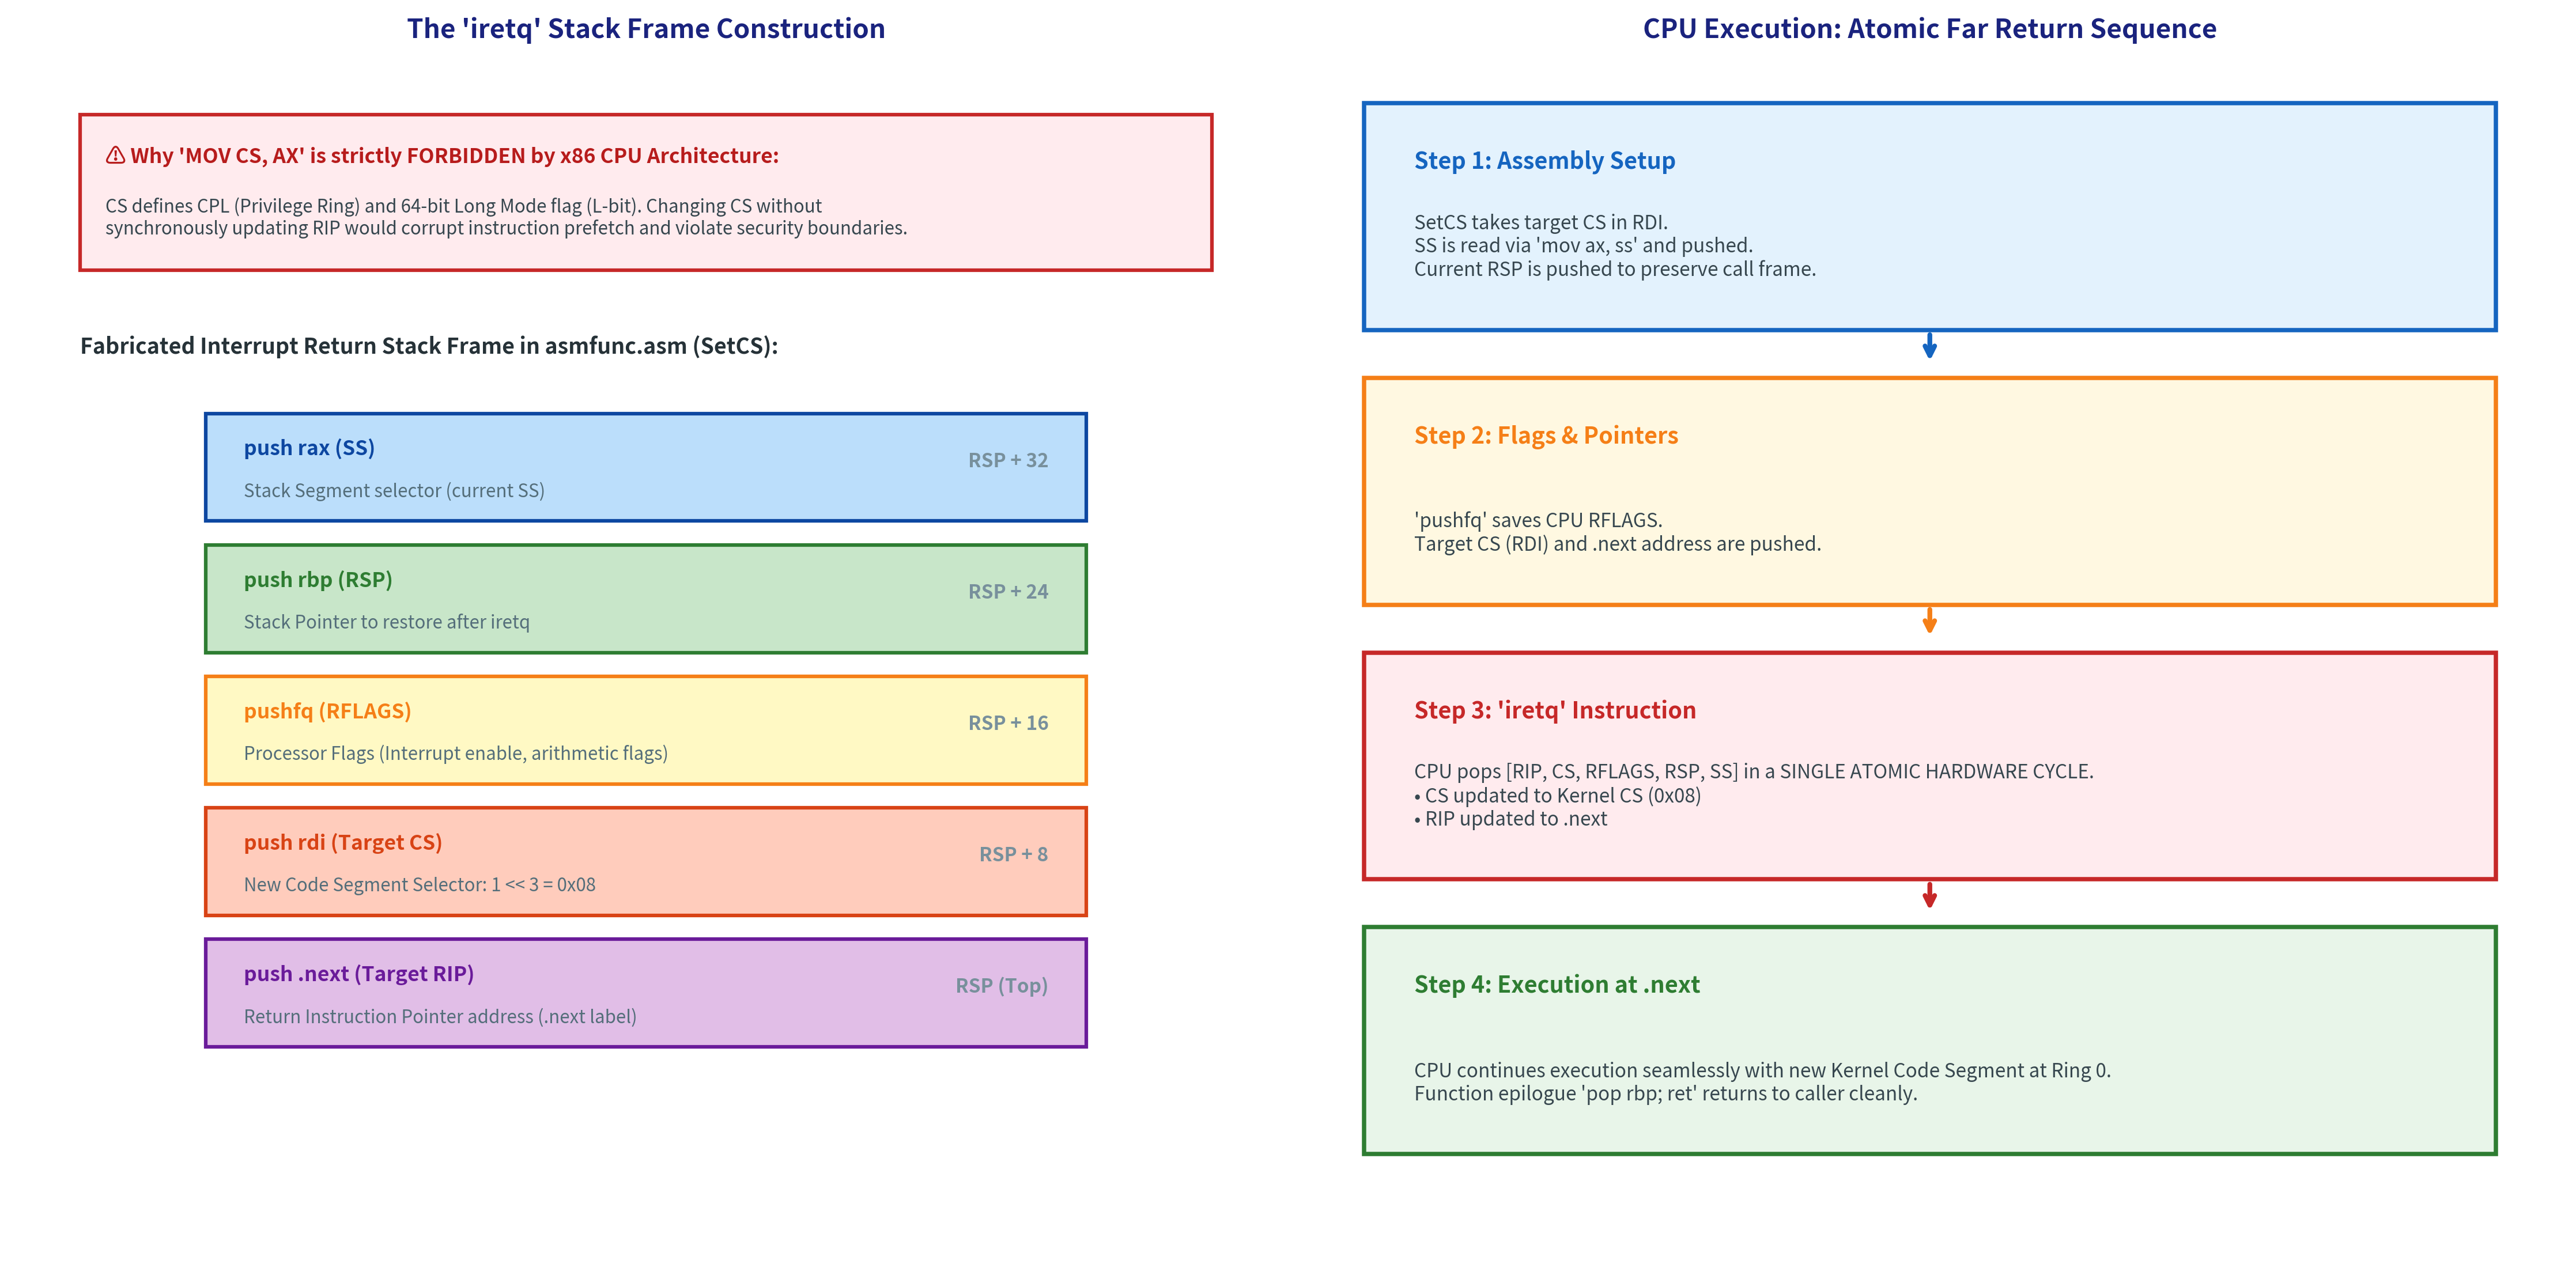

In [4]:
# 図版 8.15 の生成と表示
from common.os_sim import plot_fig8_15_cs_switch_via_iretq_mechanism
from IPython.display import Image, display

fig8_15_path = plot_fig8_15_cs_switch_via_iretq_mechanism("8/result/fig8_15_cs_switch_via_iretq_mechanism.png")
display(Image(fig8_15_path))



### 図版 8.15 の解説: `iretq` による CS 切り替えシーケンス

図版 8.15 は、スタックフレームの構築と `iretq` 命令によるアトミックなレジスタ切り替えシーケンスを図解しています：
1. **左側 (偽装スタックフレーム)**:
   - スタックの上から順に `RIP (.next)`, `CS (0x08)`, `RFLAGS`, `RSP`, `SS` が 8 バイト単位で積み上げられます。
2. **右側 (CPU 実行フロー)**:
   - `iretq` 命令が実行されると、CPU は単一のハードウェアサイクルでこれらをポップし、特権整合性を検証しながら CS を新カーネルコードセグメントに切り替えます。
   - `.next` にジャンプした後は、標準的な関数のエピローグ（`pop rbp; ret`）を経て呼び出し元へ安全にリターンします。



---

## 8.5.6 データセグメントレジスタの初期化 (`SetDSAll(0)`)

### 1. ロングモードにおけるデータセグメントレジスタの仕様

CS レジスタの切り替えに続き、MikanOS の `KernelMain` では以下の処理を実行しています：

```cpp
  SetupSegments();

  const uint16_t kernel_cs = 1 << 3; // 0x08
  SetDSAll(0);
  SetCS(kernel_cs);
```

ここで `SetDSAll(0)` は、すべてのデータセグメントレジスタ（`DS`, `ES`, `SS`, `FS`, `GS`）に **`0` (ヌルセレクタ)** をロードするアセンブリ関数です：

```nasm
global SetDSAll  ; void SetDSAll(uint16_t value);
SetDSAll:
    mov ds, di
    mov es, di
    mov ss, di
    mov fs, di
    mov gs, di
    ret
```

### 2. なぜ 0 を設定してもクラッシュしないのか？

32 ビットプロテクトモード時代は、DS や SS に 0 をロードしてメモリアクセスを行うと即座に **`#GP` (*General Protection Fault*)** 例外が発生しました。
しかし、**x86-64 Long Mode においては仕様が改定され、DS, ES, SS にヌルセレクタ（0）がロードされていても、ベースアドレスは強制的に 0、リミットチェックは無効として正常にメモリアクセスを継続できる** ようにハードウェアが設計されています。

UEFI BIOS から制御を受け継いだ直後、これらのデータセグメントレジスタには UEFI が使用していた過去のセグメントセレクタ値が残存しています。将来アプリケーション（Ring 3）を起動する際や、割り込み処理を行う際に古いセレクタが原因で予期せぬ `#GP` 例外が発生するのを防ぐため、明示的に `0` で初期化しておくことが OS の堅牢性を保つ定石となっています。



---

## 8.5.7 C++20 シミュレータによる検証と対話的実験

ホスト環境（Linux / WSL / Colab）上で動作するスタンドアロン C++20 シミュレータ（`src/ch08/gdt_segmentation_sim.cpp`）をコンパイルし、GDT 記述子のエンコード、ビットフィールド構造、セグメントセレクタの分解、および `iretq` による CS 切り替えシミュレーションを実行します。



In [5]:
# C++20 GDT & セグメンテーションシミュレータのコンパイル & 実行
import subprocess

cpp_source = "src/ch08/gdt_segmentation_sim.cpp"
bin_target = "build/bin/ch08_gdt_segmentation_sim"

# ビルドディレクトリの作成とコンパイル
os.makedirs("build/bin", exist_ok=True)
compile_cmd = ["g++", "-std=c++20", "-O2", "-Wall", "-Wextra", cpp_source, "-o", bin_target]
print("🔨 Compiling C++20 Simulator:", " ".join(compile_cmd))
res_compile = subprocess.run(compile_cmd, capture_output=True, text=True)

if res_compile.returncode != 0:
    print("❌ Compilation Failed:\n", res_compile.stderr)
else:
    print("✅ Compilation Succeeded! Executing Simulation with Unit Verification:\n")
    res_run = subprocess.run([bin_target, "--test"], capture_output=True, text=True)
    print(res_run.stdout)
    if res_run.stderr:
        print("STDERR:\n", res_run.stderr)



🔨 Compiling C++20 Simulator: g++ -std=c++20 -O2 -Wall -Wextra src/ch08/gdt_segmentation_sim.cpp -o build/bin/ch08_gdt_segmentation_sim
❌ Compilation Failed:
 cc1plus: fatal error: src/ch08/gdt_segmentation_sim.cpp: No such file or directory
compilation terminated.



In [6]:
# Python によるセグメントセレクタと記述子ビット演算の対話的検証
from common.os_sim import SegmentDescriptorSim, SegmentSelectorSim, GdtSimulator

sim = GdtSimulator()

print("=================================================================")
print(" GDT Configuration Verification")
print("=================================================================")
print(f"GDTR Limit: {sim.gdtr_limit} bytes (sizeof(GDT) - 1)")
print(f"Total Descriptors: {len(sim.descriptors)}\n")

for i, desc in enumerate(sim.descriptors):
    val = desc.to_uint64()
    print(f"GDT[{i}]: 0x{val:016X}")
    print(f"  DPL: {desc.dpl} ({'Kernel Ring 0' if desc.dpl == 0 else 'User Ring 3'})")
    print(f"  LongMode (L): {desc.long_mode}, DefaultSize (D/B): {desc.default_op_size}, Granularity (G): {desc.granularity}")
    print(f"  Raw Limit: 0x{desc.raw_limit:X}, Effective Limit: 0x{desc.effective_limit:X} ({desc.effective_limit / (1024**3):.1f} GiB)")
    print()

print("=================================================================")
print(" Segment Selector Bitfield Math")
print("=================================================================")
k_sel = SegmentSelectorSim.from_uint16(0x08)
u_sel = SegmentSelectorSim.from_uint16(0x13)

print(f"Kernel CS (0x08) -> Index: {k_sel.index}, TI: {k_sel.ti} (GDT), RPL: {k_sel.rpl} (Ring 0)")
print(f"User CS   (0x13) -> Index: {u_sel.index}, TI: {u_sel.ti} (GDT), RPL: {u_sel.rpl} (Ring 3)")

valid_k, msg_k = sim.validate_code_selector(0x08)
print(f"\nValidating Kernel CS (0x08): {valid_k} ({msg_k})")

valid_u, msg_u = sim.validate_code_selector(0x13)
print(f"Validating User CS (0x13):   {valid_u} ({msg_u})")



 GDT Configuration Verification
GDTR Limit: 23 bytes (sizeof(GDT) - 1)
Total Descriptors: 3

GDT[0]: 0x0000000000000000
  DPL: 0 (Kernel Ring 0)
  LongMode (L): 0, DefaultSize (D/B): 0, Granularity (G): 0
  Raw Limit: 0x0, Effective Limit: 0x0 (0.0 GiB)

GDT[1]: 0x00AF9A000000FFFF
  DPL: 0 (Kernel Ring 0)
  LongMode (L): 1, DefaultSize (D/B): 0, Granularity (G): 1
  Raw Limit: 0xFFFFF, Effective Limit: 0xFFFFFFFF (4.0 GiB)

GDT[2]: 0x00AFFA000000FFFF
  DPL: 3 (User Ring 3)
  LongMode (L): 1, DefaultSize (D/B): 0, Granularity (G): 1
  Raw Limit: 0xFFFFF, Effective Limit: 0xFFFFFFFF (4.0 GiB)

 Segment Selector Bitfield Math
Kernel CS (0x08) -> Index: 1, TI: 0 (GDT), RPL: 0 (Ring 0)
User CS   (0x13) -> Index: 2, TI: 0 (GDT), RPL: 3 (Ring 3)

Validating Kernel CS (0x08): True (Valid 64-bit Code Segment)
Validating User CS (0x13):   True (Valid 64-bit Code Segment)


---

## 8.5.8 本節のまとめと次節（8.6 ページングの設定）への展望

### 1. 到達目標の達成確認

| 項目 | 本節で学んだ内容・成果 |
|---|---|
| **GDT の役割** | x86-64 Long Mode においても L ビット（64 ビットモード指示）と DPL（特権レベル Ring 0 vs Ring 3）の管理に必須であることを解明。 |
| **`SegmentDescriptor` の数理** | 64 ビットのビットフィールド（Base, Limit, Type, S, DPL, P, L, D/B, G）の完全なビットレイアウトとエンコード数理を導出。 |
| **C++ のビットフィールド落とし穴** | `enum class DescriptorType : uint8_t` による符号拡張バグの防止策を確立。 |
| **セグメントセレクタの構造** | `(Index << 3) | (TI << 2) | RPL` のビット合成式により、カーネル CS `0x08`、ユーザ CS `0x13` の導出根拠を把握。 |
| **`LoadGDT` (`LGDT`)** | 10 バイト擬似記述子（16-bit Limit + 64-bit Base）を用いた GDTR レジスタの設定手順を理解。 |
| **`iretq` による CS 切り替え** | CPU が `mov cs, ax` を禁止する理由と、スタックフレーム偽装によるアトミックな CS/RIP 切り替え魔術を完全解明。 |
| **データセグメントの初期化** | `SetDSAll(0)` により UEFI の古いセレクタを破棄し、フラットモデルのヌルセレクタで初期化する安全設計を習得。 |

### 2. 次節 8.6「ページングの設定」への展望

OS 独自のスタック（8.4節）と GDT（8.5節）の確立により、CPU の実行コンテキストは UEFI の支配を脱し、カーネルの管理下に移行しました。
しかし、メモリの仮想アドレス変換を司る **ページテーブル（Page Table）** は、依然として UEFI BIOS が構築したものをそのまま利用しています。

次節 **8.6「ページングの設定」** では、OS 自身が管理する **4 階層ページテーブル（PML4, PDP, PD, PT）** をメモリ上に静的に構築し、**2 MiB 巨大ページを用いた 64 GiB 恒等マッピング（Identity Mapping）** を設定して制御レジスタ **`CR3`** を切り替えます。

